<a href="https://colab.research.google.com/github/sambhavi298/Polynomial_Regression_Lab1/blob/main/Polynomial_Regression_Lab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import PolynomialFeatures

from sklearn.linear_model import LinearRegression

from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [ ]:
df = pd.read_csv("salary_data.csv")

In [ ]:
df.head()

,YearsExperience,Salary
0,1.1,39343.0
1,1.3,46205.0
2,1.5,37731.0
3,2.0,43525.0
4,2.2,39891.0


In [ ]:
df.shape

(30, 2)

In [ ]:
df.columns

Index(['YearsExperience', 'Salary'], dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   YearsExperience  30 non-null     float64
 1   Salary           30 non-null     float64
dtypes: float64(2)
memory usage: 612.0 bytes


In [ ]:
df.describe()

,YearsExperience,Salary
count,30.000000,30.000000
mean,5.313333,76003.000000
std,2.837888,27414.429785
min,1.100000,37731.000000
25%,3.200000,56720.750000
50%,4.700000,65237.000000
75%,7.700000,100544.750000
max,10.500000,122391.000000


In [ ]:
df.isnull().sum()

,0
YearsExperience,0
Salary,0


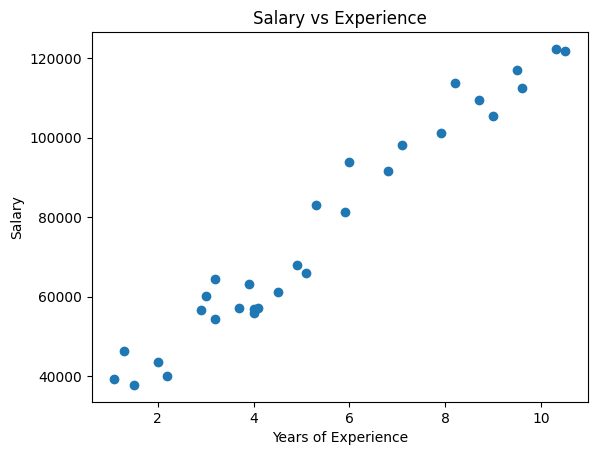

In [ ]:
plt.scatter(df["YearsExperience"], df["Salary"])

plt.xlabel("Years of Experience")

plt.ylabel("Salary")

plt.title("Salary vs Experience")

plt.show()

In [ ]:
X = df[["YearsExperience"]]

y = df["Salary"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.2,

    random_state=42

)

In [ ]:
degrees = range(1,11)

train_rmse = []

test_rmse = []

results = []

In [ ]:
for degree in degrees:

    model = Pipeline([
        ("poly", PolynomialFeatures(degree)),
        ("linear", LinearRegression())
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)

    test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_pred)

    test_mse = mean_squared_error(y_test, test_pred)

    train_rmse.append(np.sqrt(train_mse))

    test_rmse.append(np.sqrt(test_mse))

    results.append({

        "Degree": degree,

        "MSE": test_mse,

        "RMSE": np.sqrt(test_mse),

        "MAE": mean_absolute_error(y_test, test_pred),

        "R2": r2_score(y_test, test_pred)

    })

In [ ]:
results_df = pd.DataFrame(results)

results_df

,Degree,MSE,RMSE,MAE,R2
0,1,4.983010e+07,7059.043622,6286.453831,0.902446
1,2,5.252792e+07,7247.614530,6381.371430,0.897165
2,3,4.860582e+07,6971.787097,5816.262964,0.904843
3,4,4.955784e+07,7039.732755,5823.666597,0.902979
4,5,4.656048e+07,6823.524088,5281.602519,0.908847
5,6,4.467616e+07,6684.022485,4967.015316,0.912536
6,7,5.451286e+07,7383.282159,6072.286030,0.893279
7,8,5.347177e+07,7312.439600,5965.352736,0.895317
8,9,7.112888e+07,8433.793726,7267.752341,0.860749
9,10,4.970812e+07,7050.398251,5952.464429,0.902685


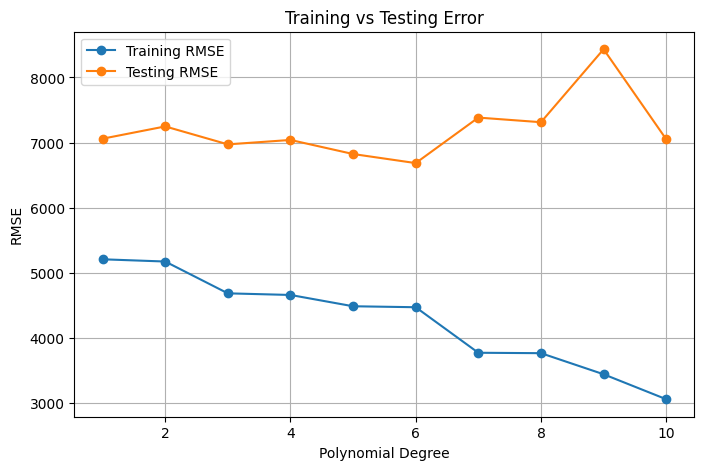

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(degrees, train_rmse, marker='o', label="Training RMSE")

plt.plot(degrees, test_rmse, marker='o', label="Testing RMSE")

plt.xlabel("Polynomial Degree")

plt.ylabel("RMSE")

plt.title("Training vs Testing Error")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
best_degree = results_df.loc[results_df["RMSE"].idxmin(),"Degree"]

print(best_degree)

6


In [ ]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("MSE :", mean_squared_error(y_test, linear_predictions))

print("RMSE :", np.sqrt(mean_squared_error(y_test, linear_predictions)))

print("MAE :", mean_absolute_error(y_test, linear_predictions))

print("R2 :", r2_score(y_test, linear_predictions))

MSE : 49830096.85590839
RMSE : 7059.04362190151
MAE : 6286.453830757749
R2 : 0.9024461774180497


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist

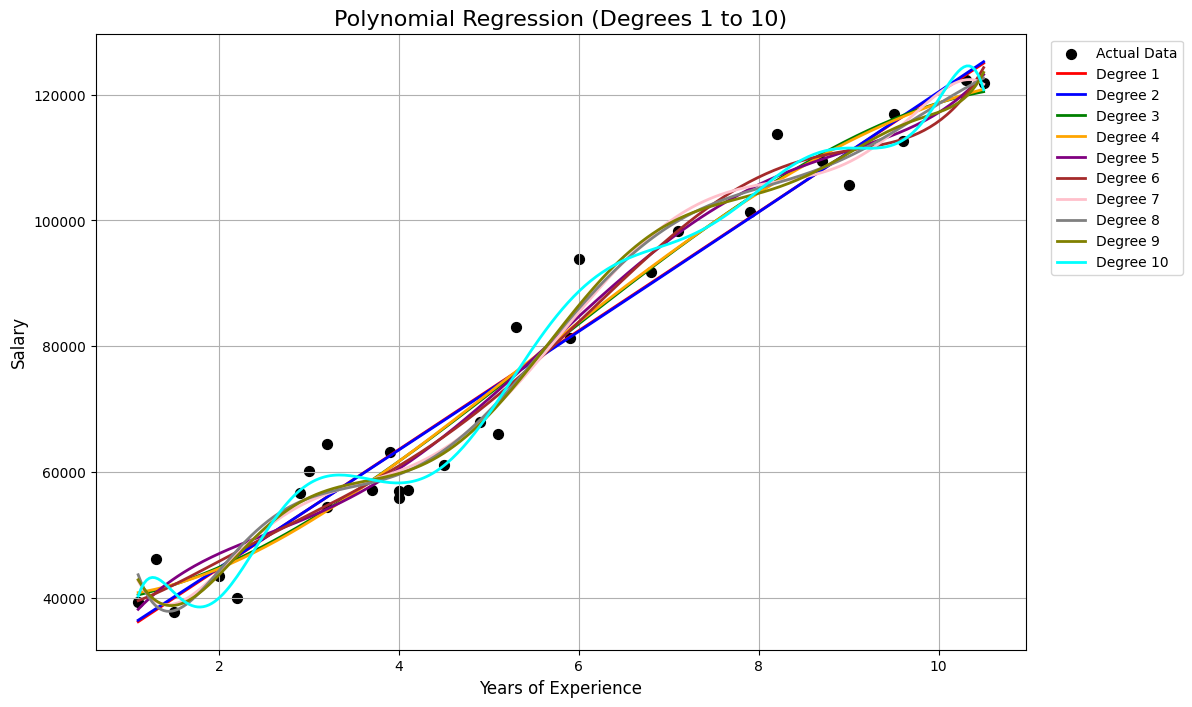

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

# Smooth values for plotting curves
X_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)

plt.figure(figsize=(12,8))

# Plot original data
plt.scatter(X, y, color='black', s=50, label='Actual Data')

# Different colors for each degree
colors = ['red','blue','green','orange','purple',
          'brown','pink','gray','olive','cyan']

for degree in range(1, 11):

    poly = PolynomialFeatures(degree=degree)

    X_poly = poly.fit_transform(X)
    X_grid_poly = poly.transform(X_grid)

    model = LinearRegression()
    model.fit(X_poly, y)

    y_pred = model.predict(X_grid_poly)

    plt.plot(X_grid,
             y_pred,
             color=colors[degree-1],
             linewidth=2,
             label=f'Degree {degree}')

plt.title('Polynomial Regression (Degrees 1 to 10)', fontsize=16)
plt.xlabel('Years of Experience', fontsize=12)
plt.ylabel('Salary', fontsize=12)
plt.legend(bbox_to_anchor=(1.02,1), loc='upper left')
plt.grid(True)

plt.show()

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist

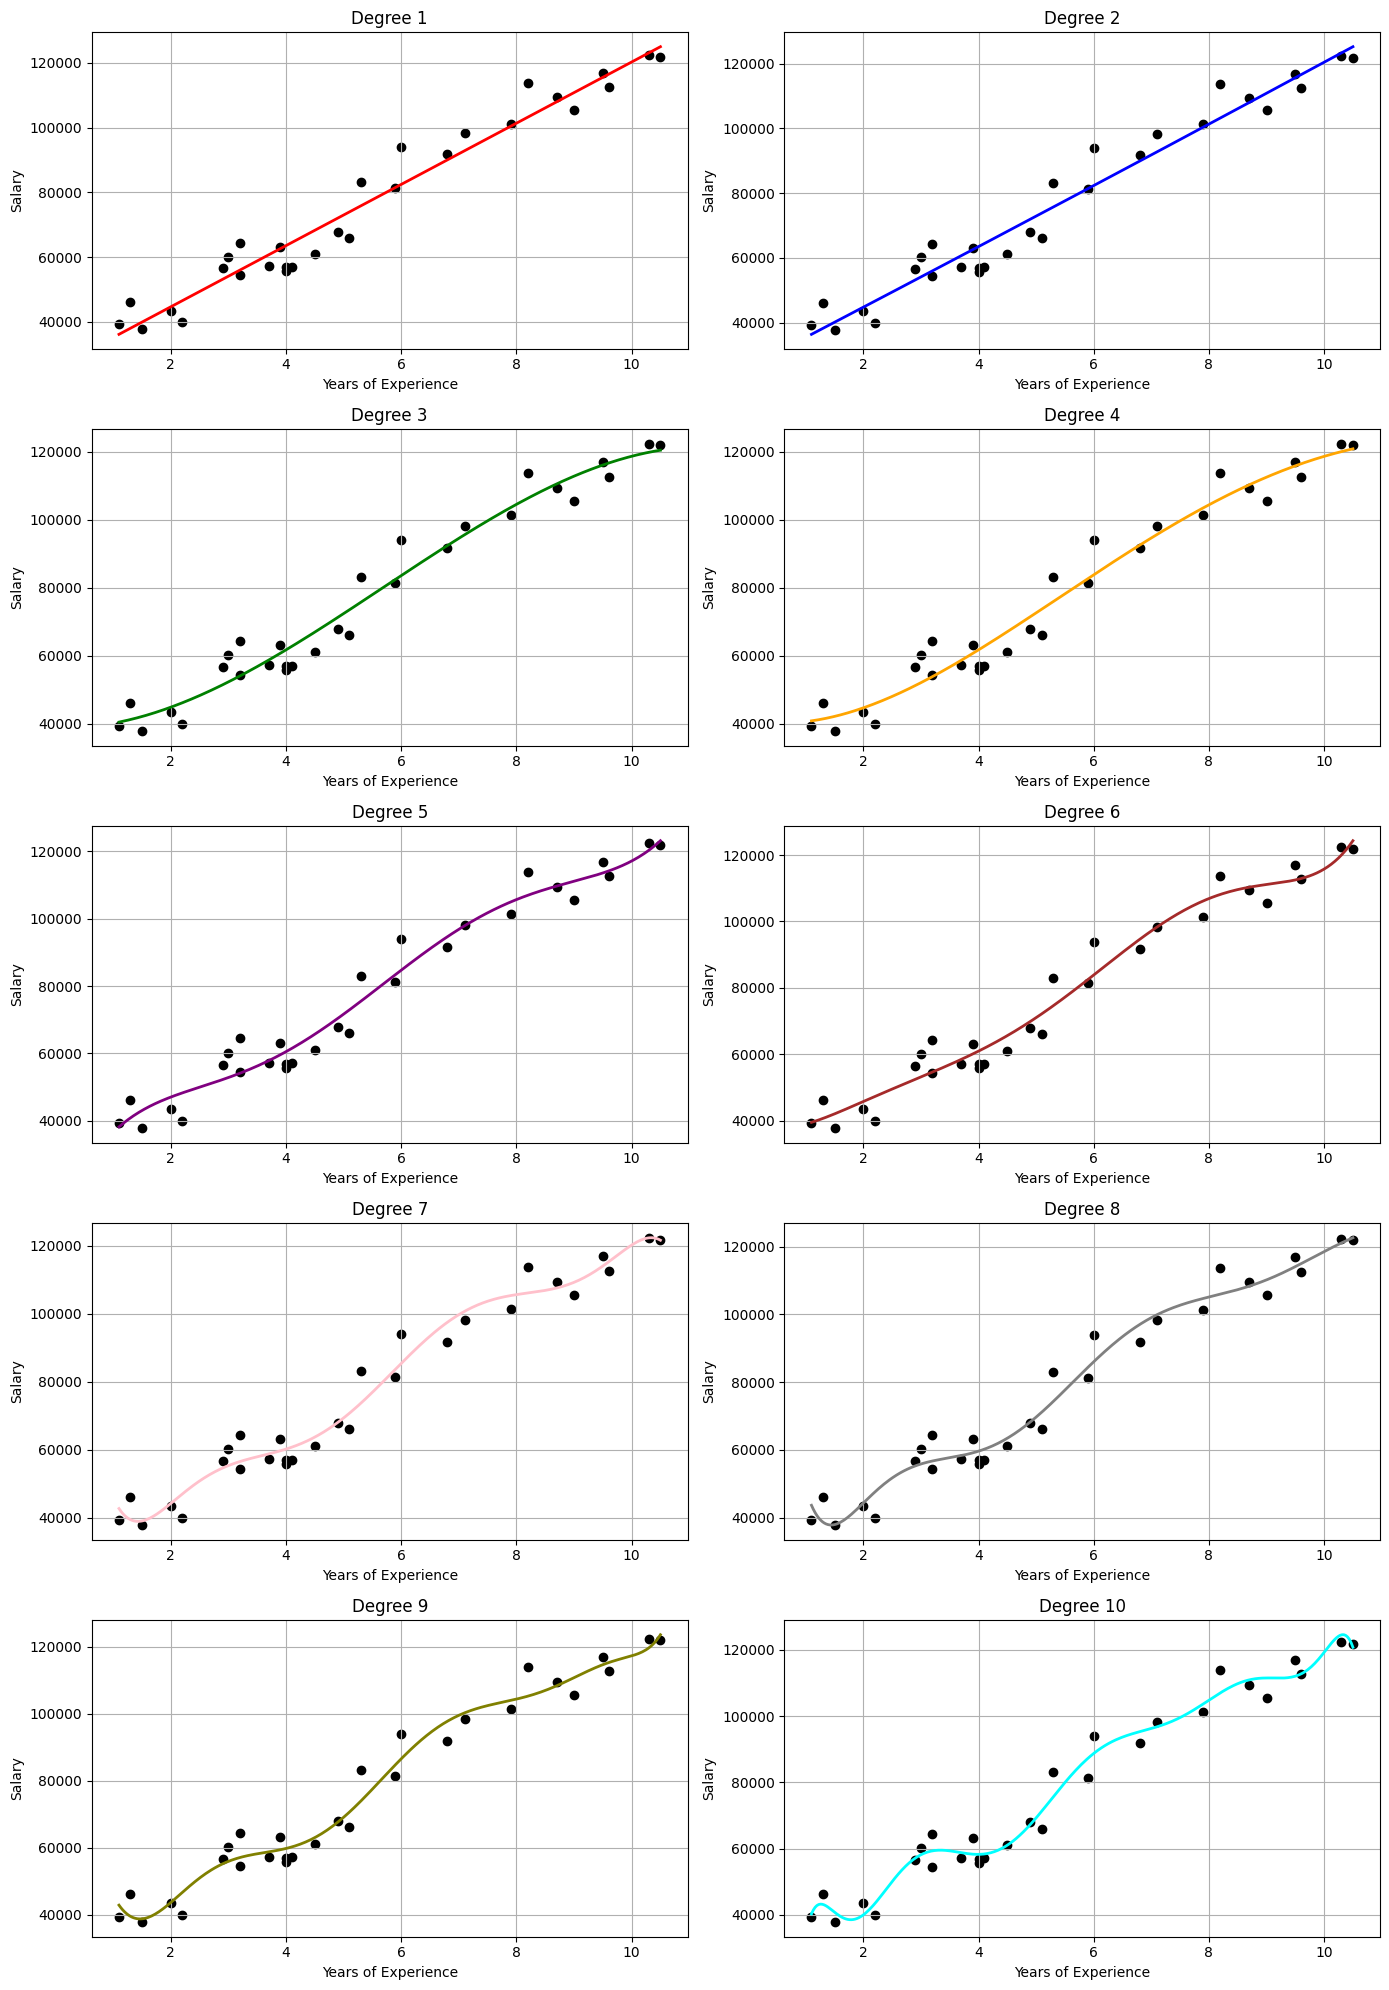

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(14,20))

axes = axes.flatten()

colors = ['red','blue','green','orange','purple',
          'brown','pink','gray','olive','cyan']

for degree in range(1, 11):

    poly = PolynomialFeatures(degree=degree)

    X_poly = poly.fit_transform(X)
    X_grid_poly = poly.transform(X_grid)

    model = LinearRegression()
    model.fit(X_poly, y)

    y_pred = model.predict(X_grid_poly)

    axes[degree-1].scatter(X, y, color='black')
    axes[degree-1].plot(X_grid,
                        y_pred,
                        color=colors[degree-1],
                        linewidth=2)

    axes[degree-1].set_title(f'Degree {degree}')
    axes[degree-1].set_xlabel('Years of Experience')
    axes[degree-1].set_ylabel('Salary')
    axes[degree-1].grid(True)

plt.tight_layout()
plt.show()